--- Tipe Data dan Struktur ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     object 
 1   Nama           99 non-null     object 
 2   Jenis_Kelamin  99 non-null     object 
 3   Prodi          99 non-null     object 
 4   Status         99 non-null     object 
 5   Nilai_Akhir    70 non-null     object 
 6   Tanggal_Ujian  99 non-null     object 
 7   Umur           90 non-null     float64
dtypes: float64(1), object(7)
memory usage: 6.3+ KB

--- Jumlah Missing Values Per Kolom ---
ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64

--- Statistik Deskriptif ---
           ID Nama Jenis_Kelamin            Prodi Status Nilai_Akhir  \
count      99   99            99               99     99   

/tmp/ipykernel_1660/1826695466.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Prodi', palette='viridis')


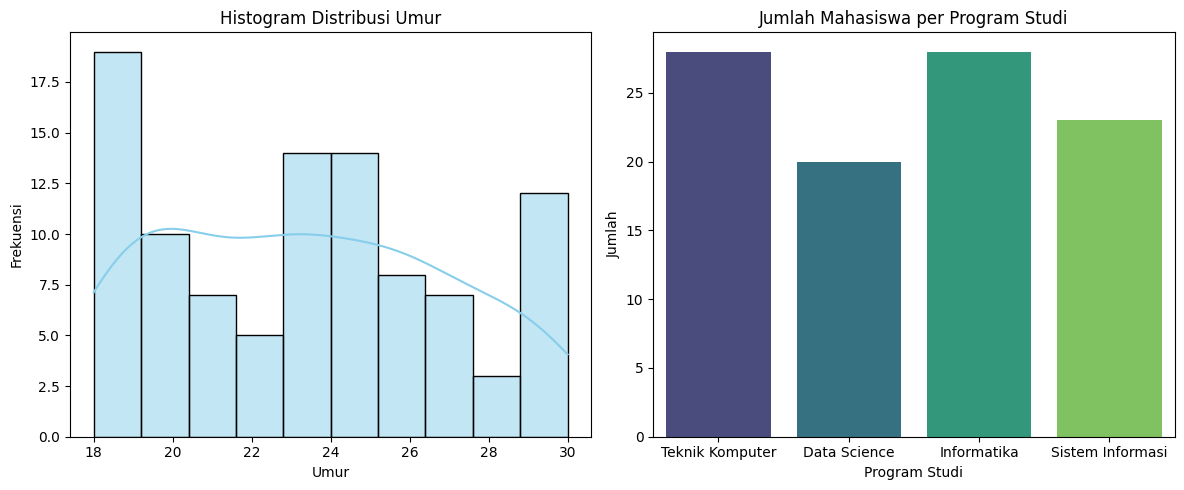

In [1]:
# ==========================================
# TAHAP 1: LOAD DATASET
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Baca file dataset ke dalam DataFrame
df = pd.read_csv('dataset_tugas1_preprocessing.csv')

# ==========================================
# TAHAP 2: EKSPLORASI AWAL (EDA)
# ==========================================
# 1. Cek struktur dan tipe data
print("--- Tipe Data dan Struktur ---")
df.info()

# 2. Tampilkan jumlah nilai hilang (missing values) per kolom
print("\n--- Jumlah Missing Values Per Kolom ---")
print(df.isnull().sum())

# 3. Sajikan statistik deskriptif
print("\n--- Statistik Deskriptif ---")
print(df.describe(include='all'))

# ==========================================
# TAHAP 3: MENANGANI MISSING VALUES
# ==========================================
# Imputasi kolom 'Umur' dengan median (karena data numerik)
df['Umur'] = df['Umur'].fillna(df['Umur'].median())

# Imputasi kolom 'Nilai_Akhir' dengan modus/nilai terbanyak (karena data kategorikal)
modus_nilai = df['Nilai_Akhir'].mode()[0]
df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(modus_nilai)

# ==========================================
# TAHAP 4: NORMALISASI FORMAT TANGGAL
# ==========================================
# Konversi kolom Tanggal_Ujian ke format datetime
df['Tanggal_Ujian'] = pd.to_datetime(df['Tanggal_Ujian'], format='mixed', dayfirst=True)

# ==========================================
# TAHAP 5: ENCODING LABEL
# ==========================================
# Label Encoding untuk kolom kategorikal
kolom_kategorikal = ['Nama', 'Jenis_Kelamin', 'Prodi', 'Status', 'Nilai_Akhir']
le = LabelEncoder()

for col in kolom_kategorikal:
    df[col + '_Encoded'] = le.fit_transform(df[col].astype(str))

# ==========================================
# TAHAP 6: SPLIT DATA
# ==========================================
# Membagi dataset menjadi data latih (80%) dan data uji (20%)
df_train, df_test = train_test_split(df, test_size=0.20, random_state=42)

print(f"Jumlah Data Latih (80%): {len(df_train)}")
print(f"Jumlah Data Uji (20%): {len(df_test)}")

# ==========================================
# TAHAP 7: VISUALISASI
# ==========================================
plt.figure(figsize=(12, 5))

# 1. Histogram untuk kolom Umur
plt.subplot(1, 2, 1)
sns.histplot(df['Umur'], kde=True, color='skyblue', bins=10)
plt.title('Histogram Distribusi Umur')
plt.xlabel('Umur')
plt.ylabel('Frekuensi')

# 2. Grafik batang jumlah mahasiswa per Prodi
plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Prodi', palette='viridis')
plt.title('Jumlah Mahasiswa per Program Studi')
plt.xlabel('Program Studi')
plt.ylabel('Jumlah')

plt.tight_layout()
plt.show()